# BreakHis v2 — stain-shift robustness, adversarial robustness and calibrated selective prediction

Patient-wise evaluation of ImageNet CNNs on **BreakHis** (benign vs malignant), extended with four things the first run showed were needed:

| # | Addition | Why |
|---|----------|-----|
| 1 | **HED stain augmentation** (vs geometry-only vs ColorJitter vs none) | Tests the draft paper's ColorJitter claim with a proper control, and a stain-aware alternative |
| 2 | **Test-time stain-shift benchmark** (HED and colour shifts, 5 severities) | Measures robustness directly instead of inferring it from training-time augmentation |
| 3 | **Adversarial robustness** (FGSM + PGD, margin loss, fp32) | Models trained on 60 patients may be fragile; ties histopathology to adversarial ML |
| 4 | **Calibration + selective prediction** (temperature scaling, validation-chosen operating points, risk-coverage) | Run 1 had recall ≈ 0.99 but specificity 0.56–0.86, and exploding validation loss = over-confidence |

Also changed after run 1: lower learning rates (backbone 5e-5 / head 5e-4), label smoothing, up to 15 epochs with **early stopping on validation AUC** (run 1 overfit from epoch 1-3, so more epochs alone would not help), and optional **patient-grouped 5-fold CV**.

**Setup:** attach the BreaKHis dataset, GPU on, Internet on. Default = 1 fold, 3 models × 4 augmentations (~2 h on a T4). Set `FOLDS_TO_RUN=[0,1,2,3,4]` for full CV (run folds in separate sessions if needed), or `QUICK_TEST=True` for a smoke test.

## 1. Imports and config

In [1]:
import os, re, glob, time, math, random, pickle, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             precision_recall_curve, average_precision_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

CFG = dict(
    MODELS=["resnet50", "densenet121", "efficientnet_b0"],
    # also available: resnext50, mobilenet_v2, vgg16, alexnet, convnext_tiny, shufflenet
    AUGS=["basic", "geom", "jitter", "hed"],
    #  basic  = resize only
    #  geom   = flips + rotation                         (control)
    #  jitter = geom + ColorJitter(.3,.3,.3,.1)          (the draft paper's "strong" tier)
    #  hed    = geom + HED stain jitter                  (stain-aware, new)
    EPOCHS=15, PATIENCE=4,                  # early stopping on validation AUC
    BATCH=32, LR_BACKBONE=5e-5, LR_HEAD=5e-4, WD=1e-2, LABEL_SMOOTH=0.1,
    IMG=224, WORKERS=4, PRETRAINED=True, FREEZE_BACKBONE=False,
    N_FOLDS=5, FOLDS_TO_RUN=[0],            # e.g. [0,1,2,3,4] for full patient-grouped CV
    HED_SIGMA=0.1, JITTER=(0.3, 0.3, 0.3, 0.1),
    SHIFT_LEVELS=[0.0, 0.1, 0.2, 0.3, 0.4],
    RUN_ROBUSTNESS=True,
    ROB_N=300, EPS=[0.5, 1.0, 2.0, 4.0], PGD_STEPS=7,      # eps in /255 pixel units
    TARGET_SENS=0.99,
    SAVE_WEIGHTS=False, QUICK_TEST=False,
)
SEED = 42
ROOT = "/kaggle/input"
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
MEAN_T = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(STD, device=device).view(1, 3, 1, 1)
print("Device:", device, "| AMP:", use_amp)

Device: cuda | AMP: True


## 2. Find the images

In [2]:
files = [f for f in glob.glob(f"{ROOT}/**/*.png", recursive=True)
         if f"{os.sep}benign{os.sep}" in f or f"{os.sep}malignant{os.sep}" in f]
assert files, "No BreakHis images found - did you attach the BreaKHis dataset via '+ Add Input'?"

NAME_RE = re.compile(r"SOB_([BM])_([A-Z]+)-(\d+-[0-9A-Za-z]+)-(\d+)-\d+", re.I)

def parse(f):
    parts = f.split(os.sep)
    m = NAME_RE.search(os.path.basename(f))
    slide_folder = os.path.basename(os.path.dirname(os.path.dirname(f)))
    return dict(path=f, label=int("malignant" in parts),
                subtype=m.group(2).upper() if m else "NA",
                patient=m.group(3) if m else slide_folder,
                magnification=(m.group(4) + "X") if m else os.path.basename(os.path.dirname(f)))

df = pd.DataFrame([parse(f) for f in files])
CLASS_NAMES = ["Benign", "Malignant"]
print(f"{len(df)} images | {df.patient.nunique()} patients | benign: {(df.label==0).sum()} | malignant: {(df.label==1).sum()}")

7909 images | 81 patients | benign: 2480 | malignant: 5429


## 3. EDA plots

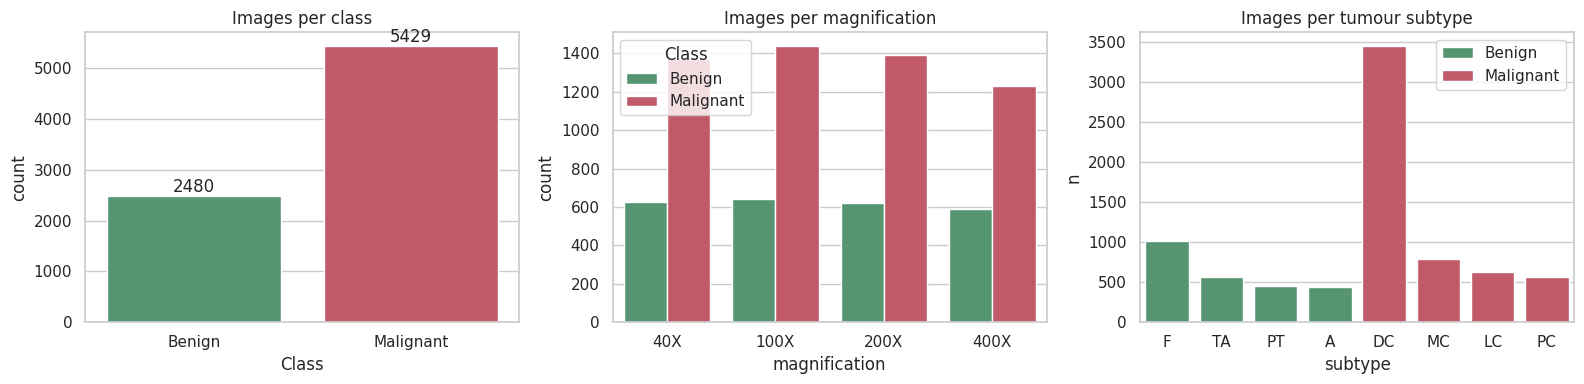

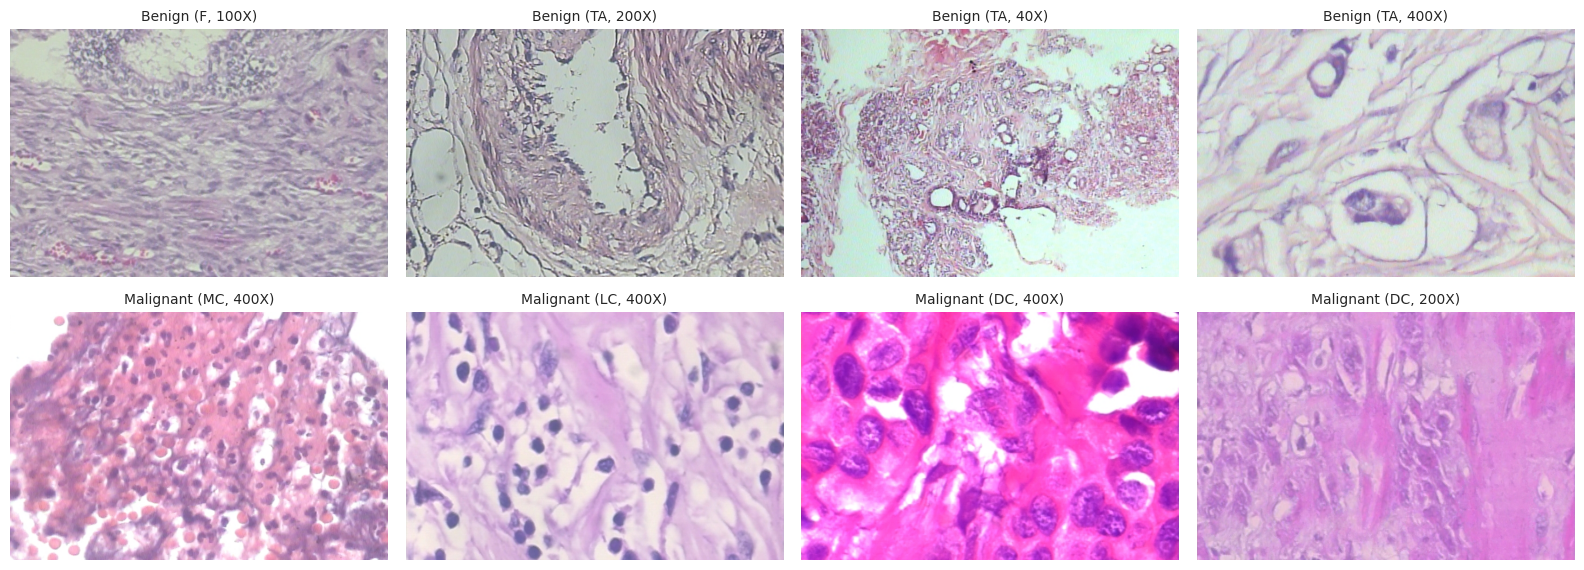

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
d2 = df.assign(Class=df.label.map(dict(enumerate(CLASS_NAMES))))
sns.countplot(data=d2, x="Class", palette=["#4C9F70", "#D1495B"], ax=axes[0]); axes[0].set_title("Images per class")
for c in axes[0].containers: axes[0].bar_label(c)
order = [o for o in ["40X", "100X", "200X", "400X"] if o in df.magnification.unique()]
sns.countplot(data=d2, x="magnification", hue="Class", order=order, palette=["#4C9F70", "#D1495B"], ax=axes[1])
axes[1].set_title("Images per magnification")
sub = df.groupby(["subtype", "label"]).size().reset_index(name="n").sort_values(["label", "n"], ascending=[True, False])
sns.barplot(data=sub, x="subtype", y="n", hue=sub.label.map(dict(enumerate(CLASS_NAMES))),
            palette=["#4C9F70", "#D1495B"], dodge=False, ax=axes[2])
axes[2].set_title("Images per tumour subtype"); axes[2].legend(title="")
fig.tight_layout(); fig.savefig(f"{OUT}/eda_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for r, lab in enumerate([0, 1]):
    for c, (_, row) in enumerate(df[df.label == lab].sample(4, random_state=1).iterrows()):
        axes[r, c].imshow(Image.open(row.path).convert("RGB")); axes[r, c].axis("off")
        axes[r, c].set_title(f"{CLASS_NAMES[lab]} ({row.subtype}, {row.magnification})", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/eda_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Patient-grouped folds

Every patient appears in exactly one test fold. Inside each fold, ~20% of the remaining patients form a validation set (used only for early stopping, temperature scaling and choosing operating points — never for reporting).

In [4]:
def group_split(d, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return [(tr, te) for tr, te in sgkf.split(d, d["label"], groups=d["patient"])]

FOLDS = []
for f, (tr_idx, te_idx) in enumerate(group_split(df, CFG["N_FOLDS"], SEED)):
    trv, te = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
    in_tr, in_va = group_split(trv, 5, SEED + f)[0]
    FOLDS.append(dict(train=trv.iloc[in_tr].reset_index(drop=True),
                      val=trv.iloc[in_va].reset_index(drop=True), test=te))

if CFG["QUICK_TEST"]:
    for fd in FOLDS:
        fd["train"] = fd["train"].sample(256, random_state=SEED).reset_index(drop=True)
        fd["val"] = fd["val"].sample(128, random_state=SEED).reset_index(drop=True)
        fd["test"] = fd["test"].sample(128, random_state=SEED).reset_index(drop=True)
    CFG.update(MODELS=CFG["MODELS"][-1:], AUGS=["basic", "hed"], EPOCHS=2, WORKERS=2,
               ROB_N=64, FOLDS_TO_RUN=[0])

rows = []
for i, fd in enumerate(FOLDS):
    s = {k: set(v.patient) for k, v in fd.items()}
    assert not (s["train"] & s["val"]) and not (s["train"] & s["test"]) and not (s["val"] & s["test"])
    for k, v in fd.items():
        rows.append(dict(fold=i, split=k, images=len(v), patients=v.patient.nunique(),
                         malignant_pct=round(100 * v.label.mean(), 1)))
display(pd.DataFrame(rows).pivot(index="fold", columns="split"))

images             patients           malignant_pct            
split   test train   val     test train val          test train   val
fold                                                                 
0       1686  5127  1096       16    53  12          75.2  68.4  59.6
1       1514  5151  1244       16    52  13          67.6  67.7  73.9
2       1740  4871  1298       16    52  13          68.2  63.1  89.8
3       1464  5202  1243       16    53  12          69.2  66.4  77.6
4       1505  4789  1615       17    51  13          62.3  70.5  69.1

## 5. Augmentations (including HED stain jitter), data, models

In [5]:
# ---- HED (haematoxylin-eosin-DAB) stain perturbation, fully in torch -----------------
RGB_FROM_HED = torch.tensor([[0.65, 0.70, 0.29],
                             [0.07, 0.99, 0.11],
                             [0.27, 0.57, 0.78]], dtype=torch.float32)   # rows = stain vectors
HED_FROM_RGB = torch.linalg.inv(RGB_FROM_HED)

def hed_perturb(x, alpha, beta):
    # x: B,3,H,W in [0,1]; alpha, beta: B,3,1,1 -> per-image scale/shift of the H, E, D stain concentrations
    R, Rinv = RGB_FROM_HED.to(x.device), HED_FROM_RGB.to(x.device)
    od = -torch.log(x.clamp(min=1e-3))                      # optical density
    c = torch.einsum("bchw,cd->bdhw", od, Rinv)             # stain concentrations
    c = c * alpha + beta
    od2 = torch.einsum("bdhw,dc->bchw", c, R)
    return torch.exp(-od2).clamp(0, 1)

class HEDJitter:
    def __init__(self, sigma): self.sigma = sigma
    def __call__(self, x):                                  # x: 3,H,W tensor in [0,1]
        a = 1 + (torch.rand(1, 3, 1, 1) * 2 - 1) * self.sigma
        b = (torch.rand(1, 3, 1, 1) * 2 - 1) * self.sigma
        return hed_perturb(x.unsqueeze(0), a, b).squeeze(0)

def color_shift(x, b, c, s):
    # brightness / contrast / saturation shift on B,3,H,W in [0,1]; b, c, s: B,1,1,1
    gray = lambda t: 0.299 * t[:, 0:1] + 0.587 * t[:, 1:2] + 0.114 * t[:, 2:3]
    x = (x * b).clamp(0, 1)
    m = gray(x).mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - m) * c + m).clamp(0, 1)
    g = gray(x)
    return (g + (x - g) * s).clamp(0, 1)

def build_tfms(aug):
    size = (CFG["IMG"], CFG["IMG"]); R = transforms.Resize(size)
    geom = [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
            transforms.RandomRotation(30, fill=255)]
    pre = {"basic": [R], "geom": [R] + geom,
           "jitter": [R] + geom + [transforms.ColorJitter(*CFG["JITTER"])],
           "hed": [R] + geom}[aug]
    post = [transforms.ToTensor()] + ([HEDJitter(CFG["HED_SIGMA"])] if aug == "hed" else []) \
           + [transforms.Normalize(MEAN, STD)]
    eval_tf = transforms.Compose([R, transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    return transforms.Compose(pre + post), eval_tf

class ImgDS(Dataset):
    def __init__(self, d, tf): self.paths, self.labels, self.tf = d.path.tolist(), d.label.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

def load_uint8(d, size):
    # preload (resized) test images as uint8 tensor N,3,H,W - used for stain-shift and adversarial evaluation
    bil = getattr(Image, "Resampling", Image).BILINEAR
    f = lambda p: np.asarray(Image.open(p).convert("RGB").resize((size, size), bil))
    with ThreadPoolExecutor(8) as ex: arr = list(ex.map(f, d.path.tolist()))
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()

def build_model(name, freeze_backbone=False):
    W = "DEFAULT" if CFG["PRETRAINED"] else None
    if name == "resnet50":          m = models.resnet50(weights=W)
    elif name == "resnext50":       m = models.resnext50_32x4d(weights=W)
    elif name == "densenet121":     m = models.densenet121(weights=W)
    elif name == "efficientnet_b0": m = models.efficientnet_b0(weights=W)
    elif name == "mobilenet_v2":    m = models.mobilenet_v2(weights=W)
    elif name == "vgg16":           m = models.vgg16(weights=W)
    elif name == "alexnet":         m = models.alexnet(weights=W)
    elif name == "convnext_tiny":   m = models.convnext_tiny(weights=W)
    elif name == "shufflenet":      m = models.shufflenet_v2_x1_0(weights=W)
    else: raise ValueError(name)
    if freeze_backbone:
        for p in m.parameters(): p.requires_grad = False
    if name in ("resnet50", "resnext50", "shufflenet"):
        m.fc = nn.Linear(m.fc.in_features, 2); head = m.fc
    elif name == "densenet121":
        m.classifier = nn.Linear(m.classifier.in_features, 2); head = m.classifier
    elif name in ("vgg16", "alexnet"):
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2); head = m.classifier[6]
    elif name in ("efficientnet_b0", "mobilenet_v2"):
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2); head = m.classifier[1]
    elif name == "convnext_tiny":
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, 2); head = m.classifier[2]
    return m.to(device), {id(p) for p in head.parameters()}

## 6. Metrics, calibration, selective prediction

In [6]:
def softmax_np(z, T=1.0):
    z = np.asarray(z, dtype=np.float64) / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def compute_metrics(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred, zero_division=0),
                Specificity=tn / (tn + fp) if (tn + fp) else 0.0,
                F1=f1_score(y, pred, zero_division=0),
                AUC=roc_auc_score(y, p) if len(set(y)) > 1 else float("nan"),
                TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn))

def patient_level_acc(d, p):
    t = d.assign(prob=np.asarray(p)).groupby("patient").agg(prob=("prob", "mean"), label=("label", "first"))
    return accuracy_score(t.label, (t.prob >= 0.5).astype(int))

def fit_temperature(z, y):
    Ts = np.linspace(0.3, 6.0, 115)
    nll = [-np.log(np.clip(softmax_np(z, T)[np.arange(len(y)), y], 1e-12, 1)).mean() for T in Ts]
    return float(Ts[int(np.argmin(nll))])

def ece_score(p, y, bins=15):
    p, y = np.asarray(p), np.asarray(y)
    conf = np.maximum(p, 1 - p); correct = ((p >= 0.5).astype(int) == y).astype(float)
    edges = np.linspace(0.5, 1.0, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def operating_points(yv, pv, yt, pt, target):
    # thresholds are chosen on VALIDATION probabilities, then applied to the test set
    out = {}
    if len(set(yv)) < 2: return out
    fpr, tpr, thr = roc_curve(yv, pv)
    cand = {"Youden": float(thr[int(np.argmax(tpr - fpr))]),
            "HighSens": float(thr[int(np.argmax(tpr >= target))])}
    for name, t in cand.items():
        pred = (pt >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
        out[name] = dict(thr=min(t, 1.0), Recall=tp / (tp + fn) if tp + fn else 0.0,
                         Specificity=tn / (tn + fp) if tn + fp else 0.0, Accuracy=(tp + tn) / len(yt))
    return out

def risk_coverage(p, y, n=40):
    conf = np.maximum(p, 1 - p); order = np.argsort(-conf)
    correct = ((p[order] >= 0.5).astype(int) == np.asarray(y)[order])
    cum = np.cumsum(correct) / np.arange(1, len(y) + 1)
    cov = np.linspace(0.3, 1.0, n)
    return cov, cum[np.clip((cov * len(y)).astype(int) - 1, 0, len(y) - 1)]

def acc_at_cov(p, y, c=0.9):
    cov, acc = risk_coverage(p, y, n=71)
    return float(acc[int(np.argmin(np.abs(cov - c)))])

## 7. Stain-shift and adversarial evaluation

In [7]:
def normalize_px(x): return (x - MEAN_T) / STD_T

def make_shift_params(n, level, seed=1234):
    g = torch.Generator().manual_seed(seed + int(round(level * 100)))
    u = lambda *s: torch.rand(*s, generator=g) * 2 - 1
    return dict(alpha=1 + u(n, 3, 1, 1) * level, beta=u(n, 3, 1, 1) * level,
                b=1 + u(n, 1, 1, 1) * level, c=1 + u(n, 1, 1, 1) * level, s=1 + u(n, 1, 1, 1) * level)

@torch.no_grad()
def predict_px(model, X, shift=None, kind=None, bs=64):
    model.eval(); outs = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(device).float() / 255.0
        if shift is not None:
            sl = {k: v[i:i + len(x)].to(device) for k, v in shift.items()}
            x = hed_perturb(x, sl["alpha"], sl["beta"]) if kind == "HED" else color_shift(x, sl["b"], sl["c"], sl["s"])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            out = model(normalize_px(x))
        outs.append(out.float().cpu())
    return torch.cat(outs).numpy()

def eval_shift(model, X, y):
    rows, base = [], None
    for lvl in CFG["SHIFT_LEVELS"]:
        params = make_shift_params(len(X), lvl) if lvl > 0 else None
        for kind in ("HED", "ColorJitter"):
            if lvl == 0:
                if base is None: base = predict_px(model, X)
                z = base
            else:
                z = predict_px(model, X, params, "HED" if kind == "HED" else "color")
            m = compute_metrics(y, softmax_np(z)[:, 1])
            rows.append(dict(kind=kind, level=lvl, Accuracy=m["Accuracy"], F1=m["F1"], AUC=m["AUC"]))
    return pd.DataFrame(rows)

def margin(logits, y):                                    # > 0 once the sample is misclassified
    return logits.gather(1, (1 - y)[:, None]).squeeze(1) - logits.gather(1, y[:, None]).squeeze(1)

def attack(model, x, y, eps, steps, step_size, rand_init):
    x_adv = x.clone()
    if rand_init: x_adv = (x_adv + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = margin(model(normalize_px(x_adv)).float(), y).sum()   # margin loss: no softmax saturation
        g, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + step_size * g.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

def eval_adv(model, X, y, n, seed=0):
    rng = np.random.RandomState(seed)
    idx = torch.as_tensor(rng.choice(len(X), size=min(n, len(X)), replace=False))
    Xs, ys = X[idx], torch.as_tensor(np.asarray(y))[idx]
    model.eval(); torch.manual_seed(seed)

    def acc_at(e255, steps, rand):
        correct = 0
        for i in range(0, len(Xs), 32):
            x = Xs[i:i + 32].to(device).float() / 255.0; yy = ys[i:i + 32].to(device)
            if e255 > 0:
                eps = e255 / 255.0
                x = attack(model, x, yy, eps, steps, eps if steps == 1 else 2.5 * eps / steps, rand)
            with torch.no_grad(): correct += (model(normalize_px(x)).argmax(1) == yy).sum().item()
        return correct / len(Xs)

    clean = acc_at(0.0, 1, False)                          # clean accuracy on the subset (shared by both attacks)
    rows = [dict(attack=a, eps=0.0, acc=clean) for a in ("FGSM", "PGD")]
    for name, steps, rand in (("FGSM", 1, False), ("PGD", CFG["PGD_STEPS"], True)):
        for e255 in CFG["EPS"]:
            rows.append(dict(attack=name, eps=e255, acc=acc_at(e255, steps, rand)))
    return pd.DataFrame(rows)

## 8. Training, early stopping, post-hoc analysis

In [8]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total, n, logits, ys = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        total += loss.item() * x.size(0); n += x.size(0)
        logits.append(out.detach().float().cpu()); ys.append(y.cpu())
    return total / n, torch.cat(logits).numpy(), torch.cat(ys).numpy()

def enrich(run):
    y, p, pr = run["y"], run["p"], run["p_raw"]
    run["metrics"] = compute_metrics(y, pr)
    run["patient_acc"] = patient_level_acc(run["test_df"], pr)
    run["ece_raw"] = ece_score(pr, y) if run["model"] != "ensemble" else float("nan")
    run["ece_cal"] = ece_score(p, y)
    run["op"] = operating_points(run["val_y"], run["val_p"], y, p, CFG["TARGET_SENS"])
    run["acc90"] = acc_at_cov(p, y, 0.9)
    return run

def fit(name, aug, fold, split, Xte):
    tr_df, va_df, te_df = split["train"], split["val"], split["test"]
    seed_everything(SEED + fold)
    train_tf, eval_tf = build_tfms(aug)
    kw = dict(batch_size=CFG["BATCH"], num_workers=CFG["WORKERS"], pin_memory=use_amp,
              persistent_workers=CFG["WORKERS"] > 0)
    train_dl = DataLoader(ImgDS(tr_df, train_tf), shuffle=True, drop_last=True, **kw)
    val_dl = DataLoader(ImgDS(va_df, eval_tf), shuffle=False, **kw)
    test_dl = DataLoader(ImgDS(te_df, eval_tf), shuffle=False, **kw)

    cnt = np.bincount(tr_df.label, minlength=2)
    cw = torch.tensor(len(tr_df) / (2.0 * np.maximum(cnt, 1)), dtype=torch.float32, device=device)
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=CFG["LABEL_SMOOTH"])

    model, head_ids = build_model(name, CFG["FREEZE_BACKBONE"])
    head_p = [p for p in model.parameters() if id(p) in head_ids]
    bb_p = [p for p in model.parameters() if id(p) not in head_ids and p.requires_grad]
    groups = [dict(params=head_p, lr=CFG["LR_HEAD"])] + ([dict(params=bb_p, lr=CFG["LR_BACKBONE"])] if bb_p else [])
    opt = torch.optim.AdamW(groups, weight_decay=CFG["WD"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    hist, best_auc, best_state, bad, t0 = [], -1.0, None, 0, time.time()
    for ep in range(1, CFG["EPOCHS"] + 1):
        tr_loss, tr_z, tr_y = run_epoch(model, train_dl, crit, opt, scaler)
        va_loss, va_z, va_y = run_epoch(model, val_dl, crit)
        sched.step()
        vm = compute_metrics(va_y, softmax_np(va_z)[:, 1])
        score = vm["AUC"] if not np.isnan(vm["AUC"]) else vm["F1"]
        hist.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss,
                         train_acc=float((tr_z.argmax(1) == tr_y).mean()), val_acc=vm["Accuracy"], val_auc=score))
        if score > best_auc:
            best_auc, bad = score, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        print(f"  ep {ep:2d}  train_loss {tr_loss:.4f}  val_loss {va_loss:.4f}  val_acc {vm['Accuracy']:.4f}  val_auc {score:.4f}")
        if bad >= CFG["PATIENCE"]:
            print(f"  early stop (best val AUC {best_auc:.4f})"); break

    model.load_state_dict(best_state)
    _, va_z, va_y = run_epoch(model, val_dl, crit)
    _, te_z, te_y = run_epoch(model, test_dl, crit)

    shift_df = adv_df = None
    if CFG["RUN_ROBUSTNESS"] and Xte is not None:
        try:   shift_df = eval_shift(model, Xte, te_y)
        except Exception as e: print("  [warn] stain-shift eval failed:", repr(e))
        try:   adv_df = eval_adv(model, Xte, te_y, CFG["ROB_N"])
        except Exception as e: print("  [warn] adversarial eval failed:", repr(e))
    if CFG["SAVE_WEIGHTS"]: torch.save(best_state, f"{OUT}/{name}_{aug}_fold{fold}.pt")

    T = fit_temperature(va_z, va_y) if len(set(va_y)) > 1 else 1.0
    run = dict(model=name, aug=aug, fold=fold, history=pd.DataFrame(hist), best_val_auc=best_auc, T=T,
               val_y=va_y, val_p=softmax_np(va_z, T)[:, 1], y=te_y, p=softmax_np(te_z, T)[:, 1],
               p_raw=softmax_np(te_z)[:, 1], test_df=te_df, shift=shift_df, adv=adv_df,
               minutes=(time.time() - t0) / 60)
    del model, opt, best_state, train_dl, val_dl, test_dl
    if use_amp: torch.cuda.empty_cache()
    return enrich(run)

def make_ensemble(fold):
    best = {}
    for (m, a, f), r in RUNS.items():
        if f == fold and (m not in best or r["best_val_auc"] > best[m]["best_val_auc"]): best[m] = r
    if len(best) < 2: return None
    mem = list(best.values())
    p = np.mean([r["p"] for r in mem], axis=0)
    run = dict(model="ensemble", aug="soft-vote", fold=fold, history=None, best_val_auc=float("nan"), T=1.0,
               val_y=mem[0]["val_y"], val_p=np.mean([r["val_p"] for r in mem], axis=0),
               y=mem[0]["y"], p=p, p_raw=p, test_df=mem[0]["test_df"], shift=None, adv=None,
               minutes=float("nan"), members=[(r["model"], r["aug"]) for r in mem])
    return enrich(run)

## 9. Run experiments (folds × models × augmentations)

In [9]:
RUNS = {}
for fold in CFG["FOLDS_TO_RUN"]:
    split = FOLDS[fold]
    Xte = load_uint8(split["test"], CFG["IMG"]) if CFG["RUN_ROBUSTNESS"] else None
    for name in CFG["MODELS"]:
        for aug in CFG["AUGS"]:
            print(f"\n=== fold {fold} | {name} + {aug} ===")
            RUNS[(name, aug, fold)] = fit(name, aug, fold, split, Xte)
            r = RUNS[(name, aug, fold)]; m = r["metrics"]
            print(f"  TEST -> acc {m['Accuracy']:.4f} | F1 {m['F1']:.4f} | AUC {m['AUC']:.4f} "
                  f"| spec {m['Specificity']:.3f} | ECE raw {r['ece_raw']:.3f} -> cal {r['ece_cal']:.3f} | {r['minutes']:.1f} min")
    ens = make_ensemble(fold)
    if ens is not None:
        RUNS[("ensemble", "soft-vote", fold)] = ens
        print(f"\nfold {fold} ensemble of {ens['members']} -> F1 {ens['metrics']['F1']:.4f}, AUC {ens['metrics']['AUC']:.4f}")
    del Xte
    try: pickle.dump(RUNS, open(f"{OUT}/runs_upto_fold{fold}.pkl", "wb"))
    except Exception as e: print("[warn] could not pickle runs:", repr(e))


=== fold 0 | resnet50 + basic ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 150MB/s] 


  ep  1  train_loss 0.4274  val_loss 0.5224  val_acc 0.8695  val_auc 0.8651
  ep  2  train_loss 0.2844  val_loss 0.4787  val_acc 0.8777  val_auc 0.8913
  ep  3  train_loss 0.2595  val_loss 0.4860  val_acc 0.8796  val_auc 0.8929
  ep  4  train_loss 0.2542  val_loss 0.4898  val_acc 0.8814  val_auc 0.8824
  ep  5  train_loss 0.2436  val_loss 0.4810  val_acc 0.8786  val_auc 0.8871
  ep  6  train_loss 0.2417  val_loss 0.4785  val_acc 0.8814  val_auc 0.9011
  ep  7  train_loss 0.2416  val_loss 0.4669  val_acc 0.8841  val_auc 0.9023
  ep  8  train_loss 0.2390  val_loss 0.4698  val_acc 0.8832  val_auc 0.9092
  ep  9  train_loss 0.2385  val_loss 0.4716  val_acc 0.8841  val_auc 0.9052
  ep 10  train_loss 0.2374  val_loss 0.4646  val_acc 0.8841  val_auc 0.9121
  ep 11  train_loss 0.2367  val_loss 0.4720  val_acc 0.8814  val_auc 0.9054
  ep 12  train_loss 0.2363  val_loss 0.4613  val_acc 0.8869  val_auc 0.9147
  ep 13  train_loss 0.2375  val_loss 0.4707  val_acc 0.8796  val_auc 0.9170
  ep 14  tra

100%|██████████| 30.8M/30.8M [00:00<00:00, 238MB/s]


  ep  1  train_loss 0.3960  val_loss 0.4752  val_acc 0.8777  val_auc 0.9005
  ep  2  train_loss 0.2809  val_loss 0.4591  val_acc 0.8777  val_auc 0.9162
  ep  3  train_loss 0.2584  val_loss 0.5008  val_acc 0.8668  val_auc 0.8917
  ep  4  train_loss 0.2612  val_loss 0.5027  val_acc 0.8796  val_auc 0.9138
  ep  5  train_loss 0.2493  val_loss 0.4724  val_acc 0.8796  val_auc 0.8960
  ep  6  train_loss 0.2495  val_loss 0.4752  val_acc 0.8759  val_auc 0.9102
  early stop (best val AUC 0.9162)
  TEST -> acc 0.8310 | F1 0.8741 | AUC 0.9623 | spec 0.986 | ECE raw 0.025 -> cal 0.027 | 6.3 min

=== fold 0 | densenet121 + geom ===
  ep  1  train_loss 0.4059  val_loss 0.4690  val_acc 0.8850  val_auc 0.8861
  ep  2  train_loss 0.3147  val_loss 0.4623  val_acc 0.8805  val_auc 0.9085
  ep  3  train_loss 0.2980  val_loss 0.4545  val_acc 0.8805  val_auc 0.9198
  ep  4  train_loss 0.2921  val_loss 0.4653  val_acc 0.8905  val_auc 0.9489
  ep  5  train_loss 0.2738  val_loss 0.4636  val_acc 0.8896  val_auc 0

100%|██████████| 20.5M/20.5M [00:00<00:00, 218MB/s]


  ep  1  train_loss 0.4369  val_loss 0.5659  val_acc 0.8631  val_auc 0.8267
  ep  2  train_loss 0.3168  val_loss 0.5597  val_acc 0.8586  val_auc 0.8263
  ep  3  train_loss 0.2824  val_loss 0.5402  val_acc 0.8714  val_auc 0.8472
  ep  4  train_loss 0.2751  val_loss 0.5070  val_acc 0.8768  val_auc 0.8818
  ep  5  train_loss 0.2710  val_loss 0.5097  val_acc 0.8823  val_auc 0.8739
  ep  6  train_loss 0.2626  val_loss 0.5213  val_acc 0.8759  val_auc 0.8666
  ep  7  train_loss 0.2584  val_loss 0.5027  val_acc 0.8805  val_auc 0.8741
  ep  8  train_loss 0.2589  val_loss 0.5063  val_acc 0.8814  val_auc 0.8830
  ep  9  train_loss 0.2560  val_loss 0.5075  val_acc 0.8859  val_auc 0.8704
  ep 10  train_loss 0.2520  val_loss 0.5184  val_acc 0.8750  val_auc 0.8741
  ep 11  train_loss 0.2518  val_loss 0.5035  val_acc 0.8841  val_auc 0.8809
  ep 12  train_loss 0.2505  val_loss 0.4964  val_acc 0.8850  val_auc 0.8797
  early stop (best val AUC 0.8830)
  TEST -> acc 0.8677 | F1 0.9057 | AUC 0.9518 | spec 

## 10. Results tables

In [10]:
SHIFT_REF = 0.3 if any(np.isclose(CFG["SHIFT_LEVELS"], 0.3)) else CFG["SHIFT_LEVELS"][-1]
EPS_REF = 2.0 if 2.0 in CFG["EPS"] else CFG["EPS"][-1]

def run_row(r):
    m, op = r["metrics"], r["op"]
    row = dict(Model=r["model"], Augmentation=r["aug"], Fold=r["fold"],
               **{k: m[k] for k in ["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC", "TP", "TN", "FP", "FN"]},
               PatientAcc=r["patient_acc"], ECE_raw=r["ece_raw"], ECE_cal=r["ece_cal"], Temp=r["T"],
               Acc_at_90cov=r["acc90"], Minutes=r["minutes"],
               Recall_HS=op.get("HighSens", {}).get("Recall", np.nan),
               Spec_HS=op.get("HighSens", {}).get("Specificity", np.nan),
               Spec_Youden=op.get("Youden", {}).get("Specificity", np.nan))
    sh = r["shift"]
    row["dF1_HED"] = row["dF1_Color"] = np.nan
    if sh is not None and len(sh):
        for kind, key in (("HED", "dF1_HED"), ("ColorJitter", "dF1_Color")):
            s = sh[sh.kind == kind]
            base = s[np.isclose(s.level, 0)].F1.iloc[0]; ref = s[np.isclose(s.level, SHIFT_REF)].F1
            row[key] = base - ref.iloc[0] if len(ref) else np.nan
    ad = r["adv"]
    row["FGSM_acc"] = row["PGD_acc"] = np.nan
    if ad is not None and len(ad):
        for atk in ("FGSM", "PGD"):
            a = ad[(ad.attack == atk) & np.isclose(ad.eps, EPS_REF)]
            row[f"{atk}_acc"] = a.acc.iloc[0] if len(a) else np.nan
    return row

results_df = pd.DataFrame([run_row(r) for r in RUNS.values()])
results_df.to_csv(f"{OUT}/results_per_fold.csv", index=False)

num_cols = [c for c in results_df.select_dtypes("number").columns if c not in ("Fold", "TP", "TN", "FP", "FN")]
grp = results_df.groupby(["Model", "Augmentation"])
summary = grp[num_cols].mean().round(4).sort_values("F1", ascending=False)
summary.to_csv(f"{OUT}/results_summary.csv")
print(f"Mean over {results_df.Fold.nunique()} fold(s).  dF1_* = F1 drop at shift level {SHIFT_REF};  FGSM/PGD_acc at eps={EPS_REF}/255;  *_HS = at validation-chosen threshold for {CFG['TARGET_SENS']:.0%} sensitivity")
display(summary[["Accuracy", "F1", "AUC", "Recall", "Specificity", "Spec_HS", "ECE_raw", "ECE_cal",
                 "Acc_at_90cov", "dF1_HED", "dF1_Color", "FGSM_acc", "PGD_acc", "PatientAcc", "Minutes"]])
if results_df.Fold.nunique() > 1:
    print("\nStd over folds:"); display(grp[["Accuracy", "F1", "AUC", "Specificity"]].std().round(4))

singles = {k: v for k, v in RUNS.items() if v["model"] != "ensemble"}
best_cfg = (results_df[results_df.Model != "ensemble"].assign(
    val=[RUNS[(r.Model, r.Augmentation, r.Fold)]["best_val_auc"] for r in results_df[results_df.Model != "ensemble"].itertuples()])
    .groupby(["Model", "Augmentation"]).val.mean().idxmax())
print("\nBest single config by mean validation AUC:", best_cfg)

Mean over 1 fold(s).  dF1_* = F1 drop at shift level 0.3;  FGSM/PGD_acc at eps=2.0/255;  *_HS = at validation-chosen threshold for 99% sensitivity


Accuracy      F1     AUC  Recall  Specificity  \
Model           Augmentation                                                  
efficientnet_b0 jitter          0.9205  0.9456  0.9751  0.9180       0.9282   
resnet50        jitter          0.9039  0.9331  0.9723  0.8904       0.9450   
densenet121     geom            0.9039  0.9327  0.9755  0.8856       0.9593   
ensemble        soft-vote       0.9033  0.9317  0.9858  0.8770       0.9833   
densenet121     jitter          0.9015  0.9307  0.9766  0.8785       0.9713   
efficientnet_b0 hed             0.8903  0.9222  0.9732  0.8644       0.9689   
                geom            0.8867  0.9194  0.9749  0.8588       0.9713   
densenet121     hed             0.8725  0.9085  0.9606  0.8423       0.9641   
efficientnet_b0 basic           0.8677  0.9057  0.9518  0.8446       0.9378   
resnet50        hed             0.8677  0.9053  0.9646  0.8407       0.9498   
                geom            0.8541  0.8934  0.9687  0.8131       0.9785   
                basic           0.8511  0.8912  0.9625  0.8107       0.9737   
densenet121     basic           0.8310  0.8741  0.9623  0.7800       0.9856   

                              Spec_HS  ECE_raw  ECE_cal  Acc_at_90cov  \
Model           Augmentation                                            
efficientnet_b0 jitter         0.9593   0.0811   0.0878        0.9558   
resnet50        jitter         0.9426   0.0519   0.0575        0.9407   
densenet121     geom           0.9809   0.0512   0.0577        0.9374   
ensemble        soft-vote      0.9904      NaN   0.0699        0.9387   
densenet121     jitter         0.9569   0.0624   0.0489        0.9367   
efficientnet_b0 hed            0.9737   0.0516   0.0604        0.9176   
                geom           0.9785   0.0436   0.0648        0.9143   
densenet121     hed            0.8565   0.0439   0.0422        0.9064   
efficientnet_b0 basic          0.9689   0.0402   0.0572        0.8965   
resnet50        hed            0.8947   0.0354   0.0308        0.9071   
                geom           0.9545   0.0344   0.0351        0.8860   
                basic          0.9785   0.0555   0.0516        0.8866   
densenet121     basic          0.9474   0.0255   0.0272        0.8589   

                              dF1_HED  dF1_Color  FGSM_acc  PGD_acc  \
Model           Augmentation                                          
efficientnet_b0 jitter         0.1569     0.0067    0.2567   0.0000   
resnet50        jitter         0.1259     0.0138    0.4000   0.0000   
densenet121     geom           0.1418     0.0535    0.2200   0.0067   
ensemble        soft-vote         NaN        NaN       NaN      NaN   
densenet121     jitter         0.1612     0.0133    0.0933   0.0000   
efficientnet_b0 hed            0.0847     0.0850    0.2067   0.0000   
                geom           0.1308     0.0747    0.2367   0.0000   
densenet121     hed            0.0593     0.0582    0.0667   0.0000   
efficientnet_b0 basic          0.1203     0.0527    0.2133   0.0000   
resnet50        hed            0.0674     0.0582    0.3033   0.0000   
                geom           0.0972     0.0676    0.3700   0.0033   
                basic          0.0871     0.0488    0.3733   0.0000   
densenet121     basic          0.1236     0.0708    0.0533   0.0000   

                              PatientAcc  Minutes  
Model           Augmentation                       
efficientnet_b0 jitter            1.0000  13.0468  
resnet50        jitter            1.0000  11.1075  
densenet121     geom              1.0000   7.8523  
ensemble        soft-vote         0.9375      NaN  
densenet121     jitter            0.9375   9.6519  
efficientnet_b0 hed               0.9375  11.7850  
                geom              0.8750  11.2229  
densenet121     hed               1.0000   8.3427  
efficientnet_b0 basic             0.9375   9.7424  
resnet50        hed               1.0000  10.1626  
                geom              0.8125   9.7975  
      


Best single config by mean validation AUC: ('densenet121', 'jitter')


## 11. Plots — training and overall performance

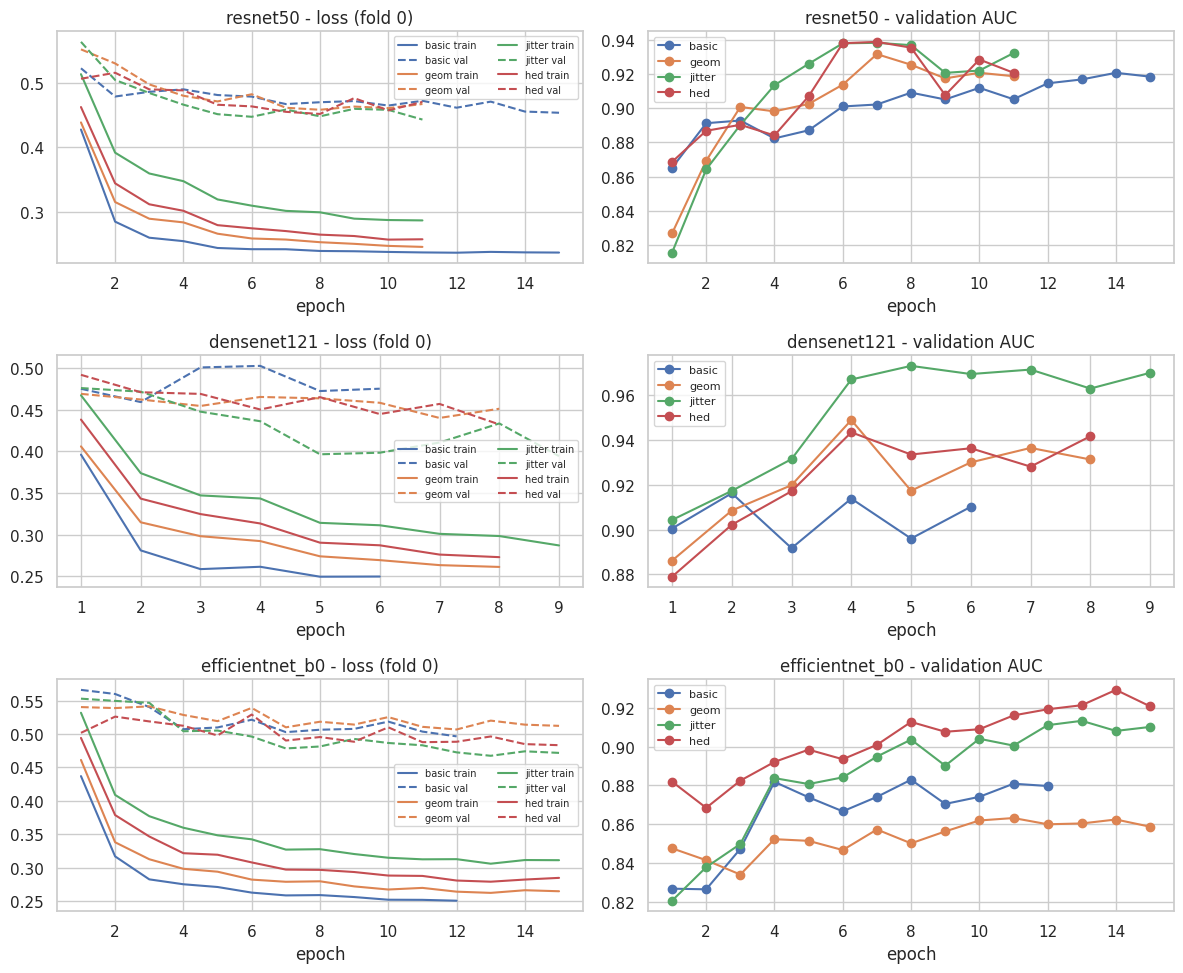

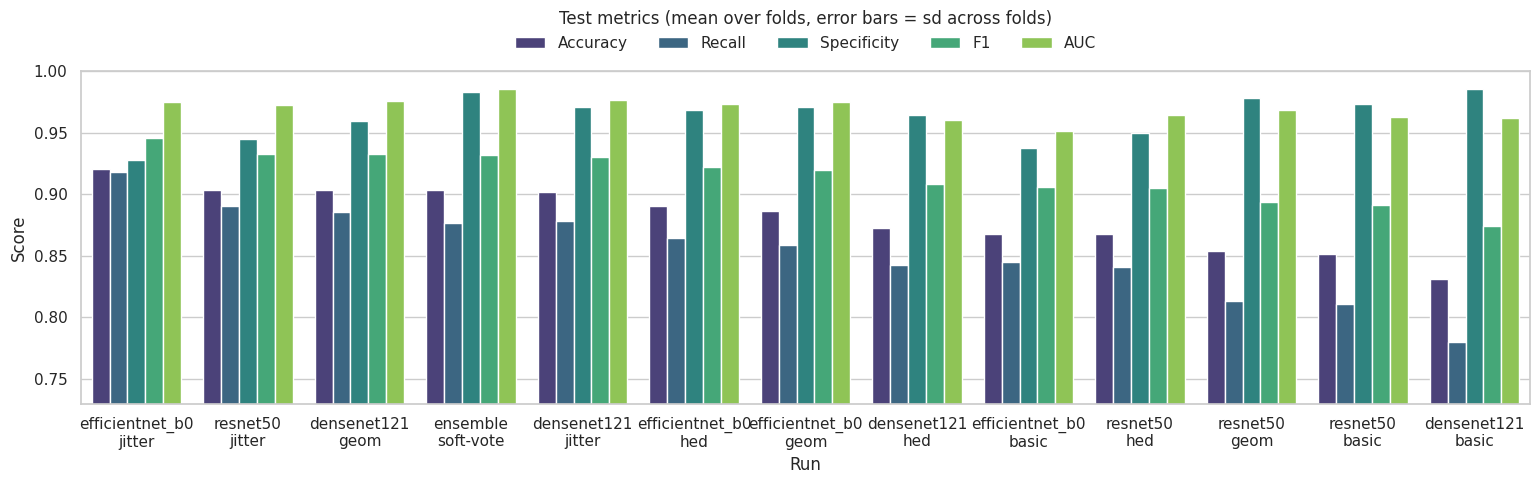

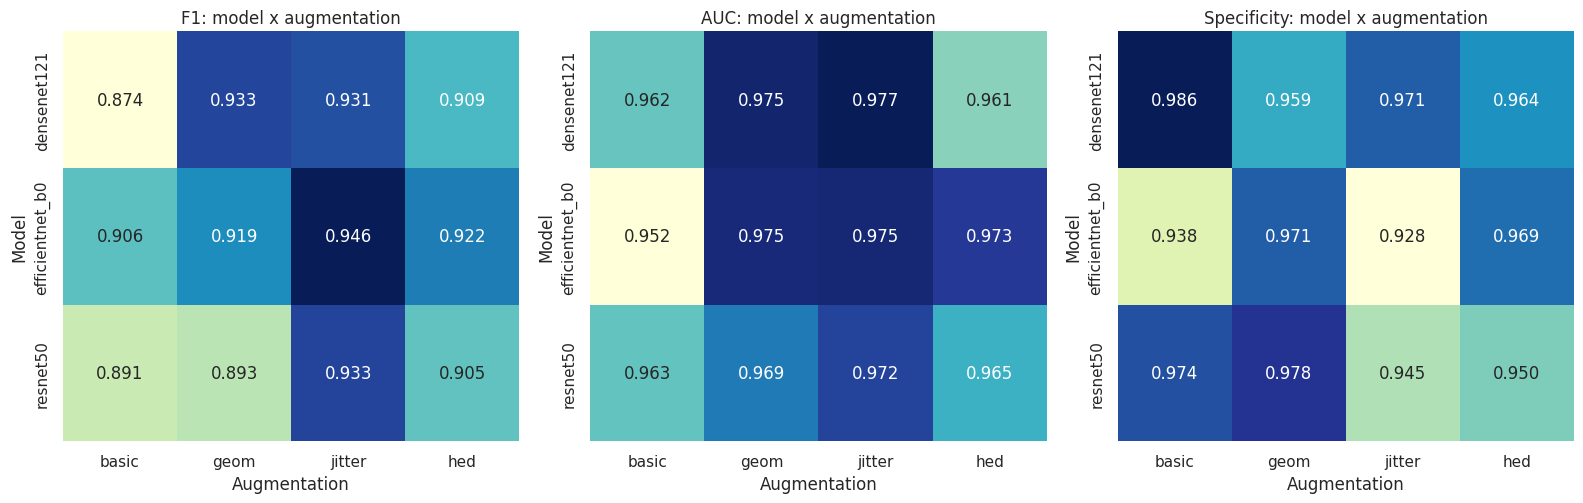

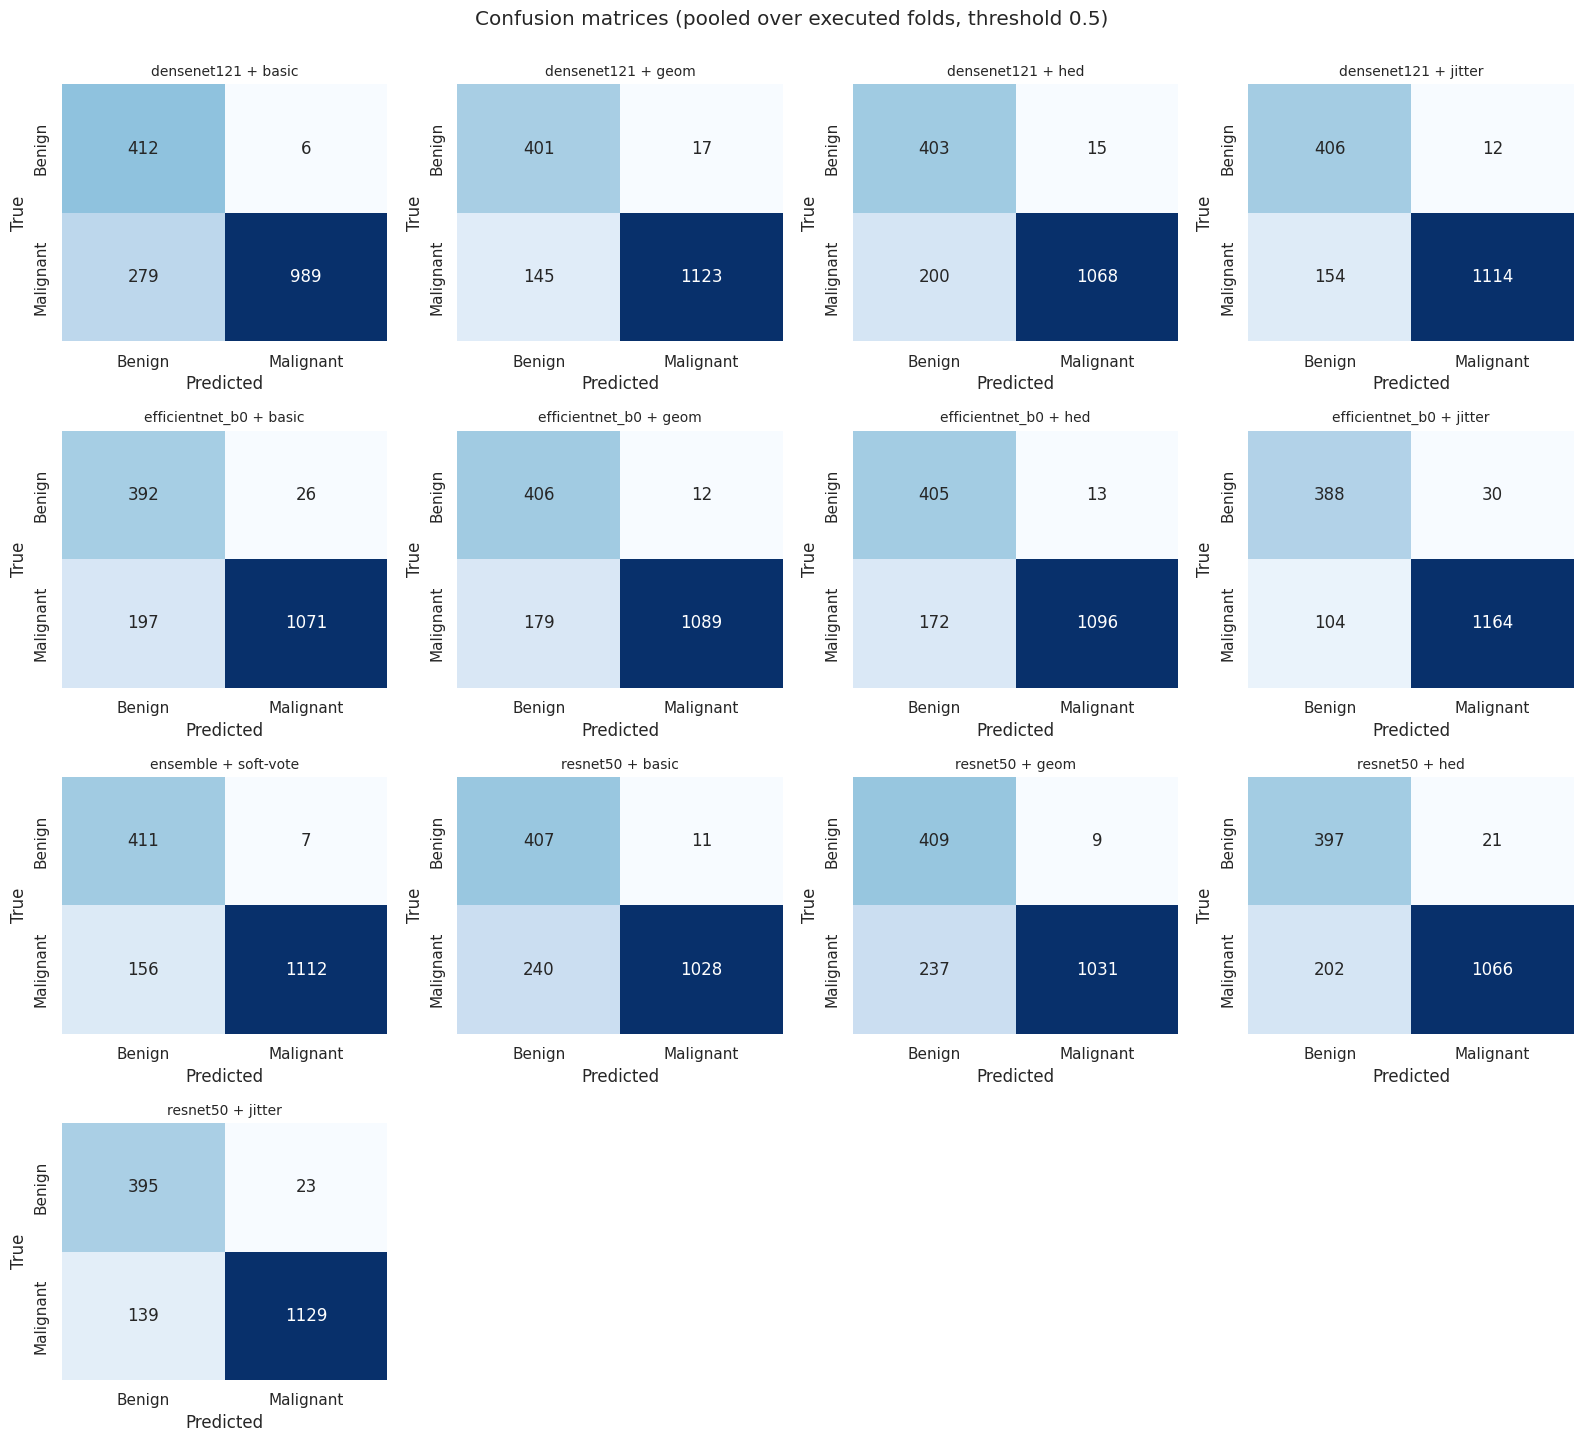

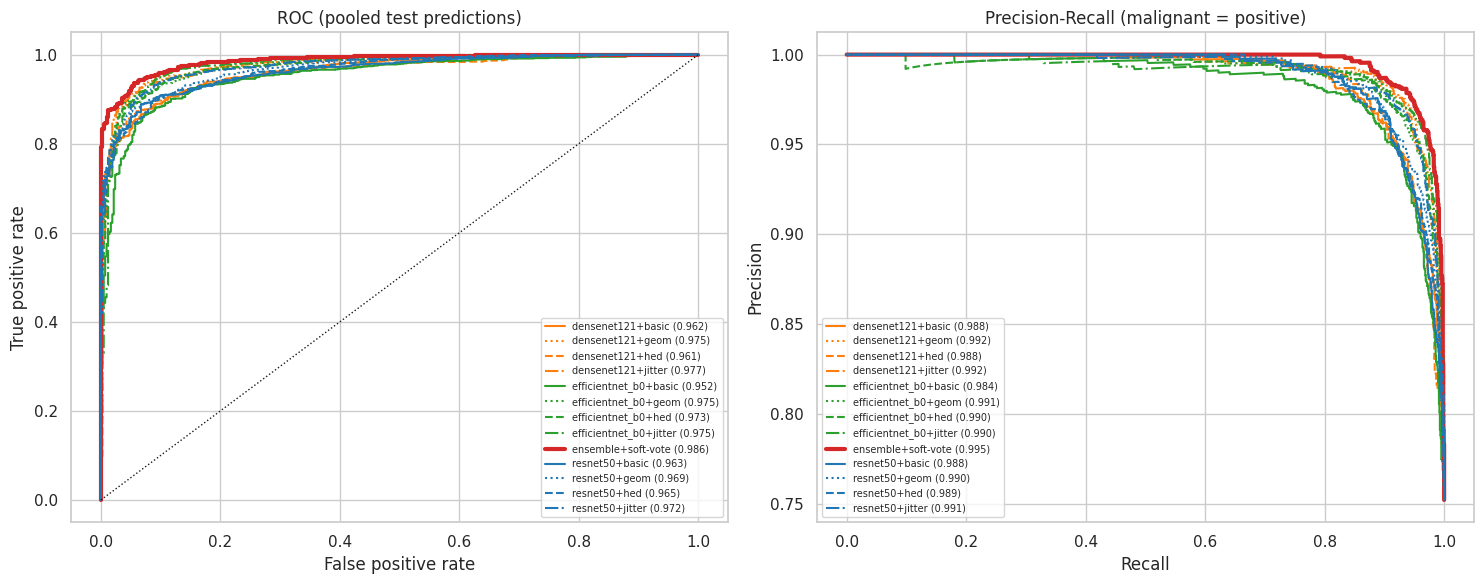

In [11]:
AUGS = CFG["AUGS"]; models_run = list(dict.fromkeys(m for (m, a, f) in RUNS if m != "ensemble"))
PAL = dict(zip(["basic", "geom", "jitter", "hed"], sns.color_palette("deep", 4)))
f0 = CFG["FOLDS_TO_RUN"][0]

fig, axes = plt.subplots(len(models_run), 2, figsize=(12, 3.3 * len(models_run)), squeeze=False)
for i, m in enumerate(models_run):
    for aug in AUGS:
        r = RUNS.get((m, aug, f0))
        if r is None: continue
        h = r["history"]
        axes[i, 0].plot(h.epoch, h.train_loss, color=PAL[aug], ls="-", label=f"{aug} train")
        axes[i, 0].plot(h.epoch, h.val_loss, color=PAL[aug], ls="--", label=f"{aug} val")
        axes[i, 1].plot(h.epoch, h.val_auc, color=PAL[aug], marker="o", label=aug)
    axes[i, 0].set_title(f"{m} - loss (fold {f0})"); axes[i, 0].set_xlabel("epoch"); axes[i, 0].legend(fontsize=7, ncol=2)
    axes[i, 1].set_title(f"{m} - validation AUC"); axes[i, 1].set_xlabel("epoch"); axes[i, 1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

metric_cols = ["Accuracy", "Recall", "Specificity", "F1", "AUC"]
long = results_df.assign(Run=results_df.Model + "\n" + results_df.Augmentation).melt(
    id_vars=["Run", "Fold"], value_vars=metric_cols, var_name="Metric", value_name="Score")
order = results_df.assign(Run=results_df.Model + "\n" + results_df.Augmentation).groupby("Run").F1.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(max(11, 1.2 * len(order)), 5))
sns.barplot(data=long, x="Run", y="Score", hue="Metric", order=order, errorbar="sd", ax=ax, palette="viridis")
ax.set_ylim(max(0, long.Score.min() - 0.05), 1.0)
ax.set_title("Test metrics (mean over folds, error bars = sd across folds)", pad=34)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/metrics_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

g = results_df[results_df.Model != "ensemble"]
fig, axes = plt.subplots(1, 3, figsize=(16, 0.9 * g.Model.nunique() + 2.5))
for ax, met in zip(axes, ["F1", "AUC", "Specificity"]):
    sns.heatmap(g.pivot_table(index="Model", columns="Augmentation", values=met, aggfunc="mean")[[a for a in AUGS if a in g.Augmentation.unique()]],
                annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, cbar=False)
    ax.set_title(f"{met}: model x augmentation")
fig.tight_layout(); fig.savefig(f"{OUT}/heatmap_model_aug.png", dpi=150, bbox_inches="tight"); plt.show()

def pooled(model, aug, key="p"):
    rs = [r for (m, a, f), r in RUNS.items() if m == model and a == aug]
    return np.concatenate([r["y"] for r in rs]), np.concatenate([r[key] for r in rs])

cm_sum = results_df.groupby(["Model", "Augmentation"])[["TP", "TN", "FP", "FN"]].sum()
keys = list(cm_sum.index); ncol = min(4, len(keys)); nrow = math.ceil(len(keys) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.6 * nrow), squeeze=False)
for ax, k in zip(axes.ravel(), keys):
    r = cm_sum.loc[k]; cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{k[0]} + {k[1]}", fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for ax in axes.ravel()[len(keys):]: ax.axis("off")
fig.suptitle("Confusion matrices (pooled over executed folds, threshold 0.5)", y=1.0)
fig.tight_layout(); fig.savefig(f"{OUT}/confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
col = {m: c for m, c in zip(models_run + ["ensemble"], sns.color_palette("tab10", len(models_run) + 1))}
ls = {"basic": "-", "geom": ":", "jitter": "-.", "hed": "--", "soft-vote": "-"}
for (m, a), _ in cm_sum.groupby(level=[0, 1]):
    y, p = pooled(m, a)
    fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
    lw = 3 if m == "ensemble" else 1.5
    axes[0].plot(fpr, tpr, color=col[m], ls=ls[a], lw=lw, label=f"{m}+{a} ({roc_auc_score(y, p):.3f})")
    axes[1].plot(rc, pr, color=col[m], ls=ls[a], lw=lw, label=f"{m}+{a} ({average_precision_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(title="ROC (pooled test predictions)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-Recall (malignant = positive)", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=7, loc="lower right"); axes[1].legend(fontsize=7, loc="lower left")
fig.tight_layout(); fig.savefig(f"{OUT}/roc_pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Novel analysis A — stain-shift robustness

Each trained model is evaluated on the **same** test images after a controlled synthetic stain shift (random per-image HED-concentration scaling/offset, or brightness/contrast/saturation change), at severities 0 → 0.4. Training-time `jitter` vs `hed` vs `geom` answers: *does colour augmentation help or hurt, and does stain-aware augmentation help more than generic jitter?*

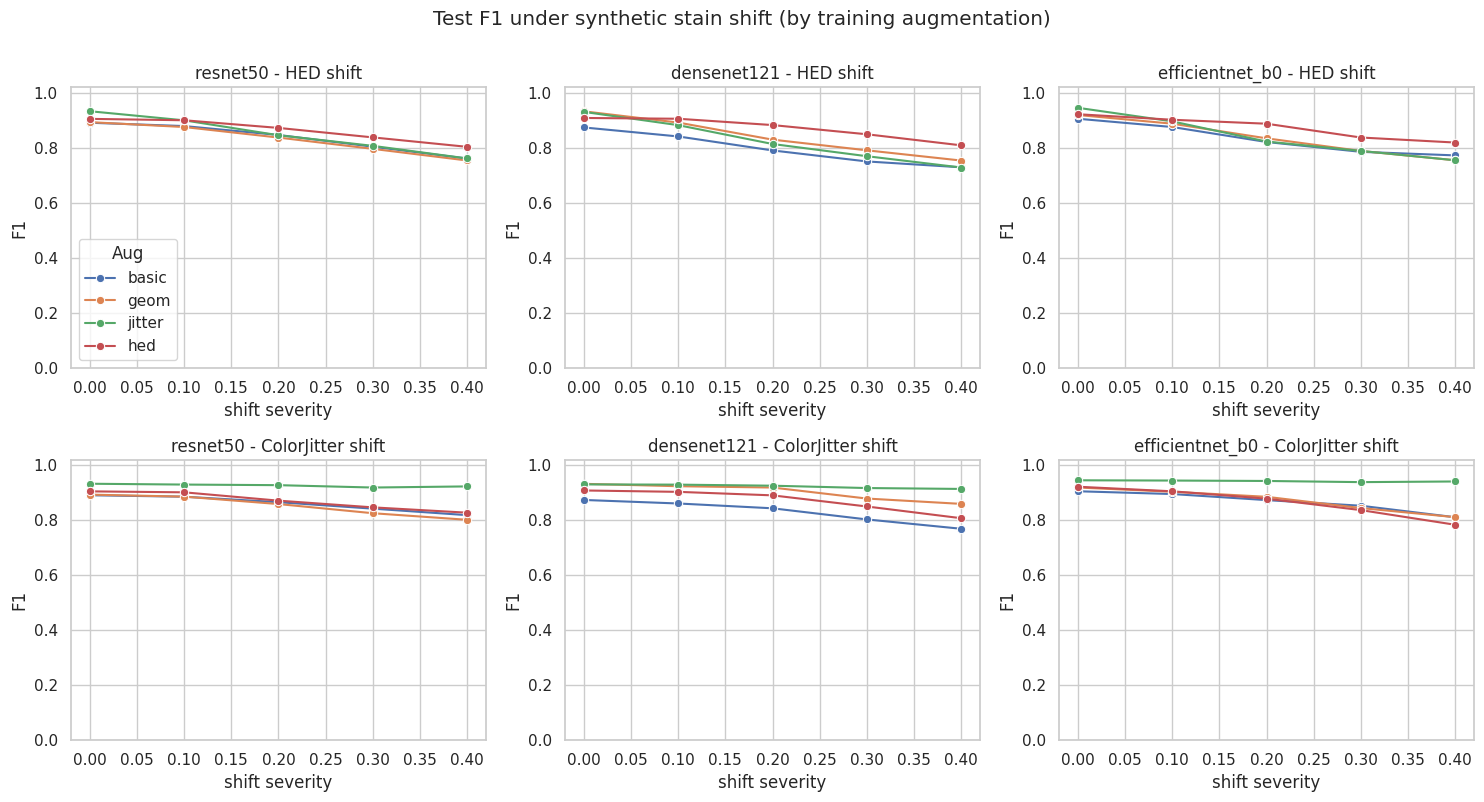

Mean F1 over all severities (higher = more robust):


kind                    ColorJitter     HED
Model           Aug                        
densenet121     basic        0.8303  0.7971
                geom         0.9030  0.8398
                hed          0.8722  0.8711
                jitter       0.9236  0.8250
efficientnet_b0 basic        0.8678  0.8321
                geom         0.8730  0.8370
                hed          0.8655  0.8737
                jitter       0.9427  0.8416
resnet50        basic        0.8609  0.8364
                geom         0.8533  0.8313
                hed          0.8707  0.8639
                jitter       0.9267  0.8494

In [12]:
shift_all = pd.concat([r["shift"].assign(Model=r["model"], Aug=r["aug"], Fold=r["fold"])
                       for r in RUNS.values() if r["shift"] is not None and len(r["shift"])], ignore_index=True) \
            if any(r["shift"] is not None for r in RUNS.values()) else pd.DataFrame()
if len(shift_all):
    shift_all.to_csv(f"{OUT}/stain_shift_results.csv", index=False)
    kinds = ["HED", "ColorJitter"]
    fig, axes = plt.subplots(len(kinds), len(models_run), figsize=(5 * len(models_run), 4 * len(kinds)), squeeze=False)
    for i, k in enumerate(kinds):
        for j, m in enumerate(models_run):
            d = shift_all[(shift_all.kind == k) & (shift_all.Model == m)]
            sns.lineplot(data=d, x="level", y="F1", hue="Aug", hue_order=[a for a in AUGS if a in d.Aug.unique()],
                         palette=PAL, marker="o", errorbar="sd", ax=axes[i, j])
            axes[i, j].set_title(f"{m} - {k} shift"); axes[i, j].set_xlabel("shift severity"); axes[i, j].set_ylim(0, 1.02)
            if i or j: axes[i, j].legend_.remove() if axes[i, j].get_legend() else None
    fig.suptitle("Test F1 under synthetic stain shift (by training augmentation)", y=1.0)
    fig.tight_layout(); fig.savefig(f"{OUT}/stain_shift_robustness.png", dpi=150, bbox_inches="tight"); plt.show()

    area = shift_all.groupby(["Model", "Aug", "kind"]).F1.mean().unstack("kind").round(4)
    print("Mean F1 over all severities (higher = more robust):"); display(area)
else:
    print("No stain-shift results (RUN_ROBUSTNESS=False?)")

## 13. Novel analysis B — adversarial robustness

White-box **FGSM** and **PGD** (L∞, margin loss, fp32) on a fixed random subset of the test images; eps is in /255 pixel units. Accuracy at eps = 0 is the clean accuracy on that subset.

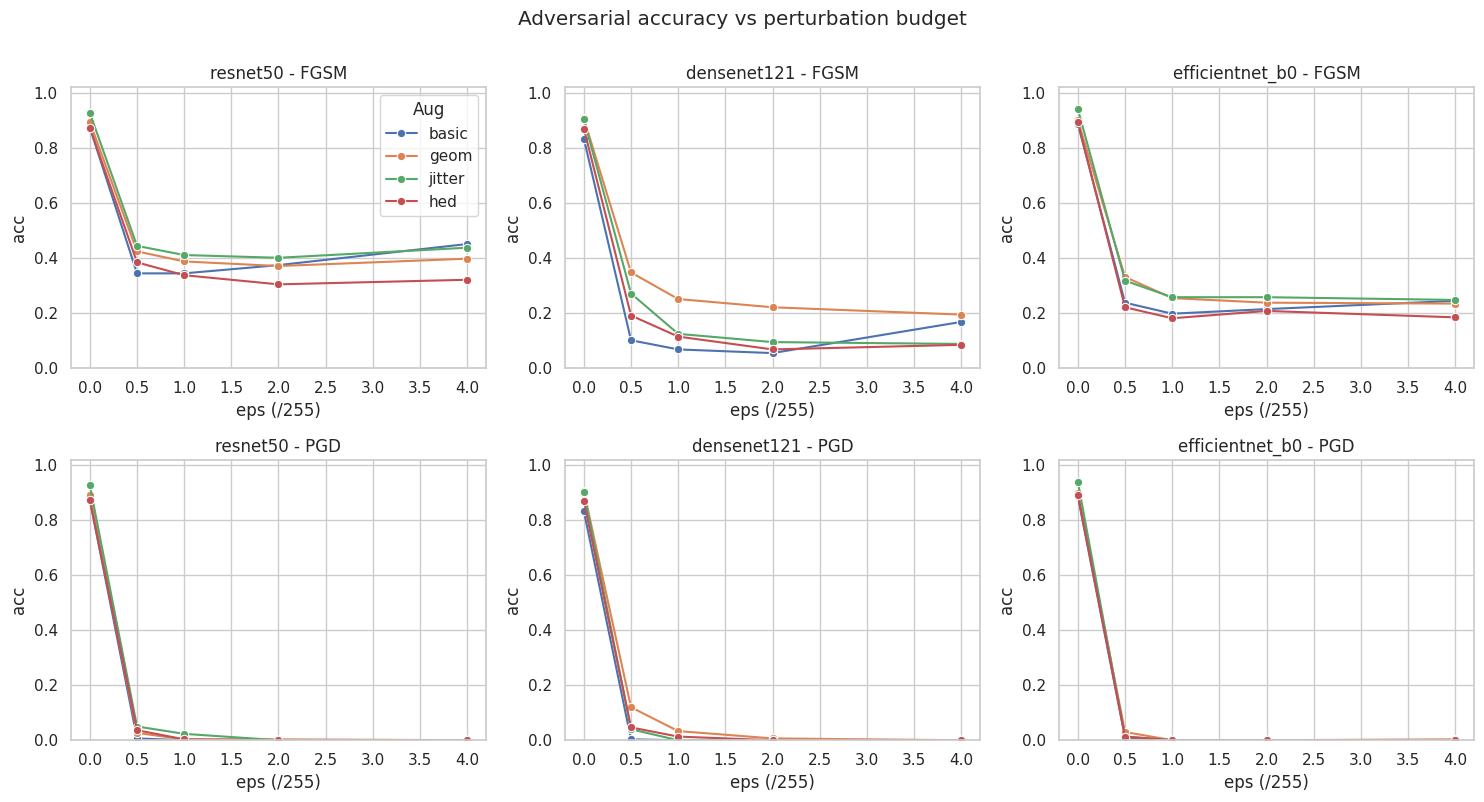

attack                   FGSM    PGD
Model           Aug                 
densenet121     basic   0.053  0.000
                geom    0.220  0.007
                hed     0.067  0.000
                jitter  0.093  0.000
efficientnet_b0 basic   0.213  0.000
                geom    0.237  0.000
                hed     0.207  0.000
                jitter  0.257  0.000
resnet50        basic   0.373  0.000
                geom    0.370  0.003
                hed     0.303  0.000
                jitter  0.400  0.000

In [13]:
adv_all = pd.concat([r["adv"].assign(Model=r["model"], Aug=r["aug"], Fold=r["fold"])
                     for r in RUNS.values() if r["adv"] is not None and len(r["adv"])], ignore_index=True) \
          if any(r["adv"] is not None for r in RUNS.values()) else pd.DataFrame()
if len(adv_all):
    adv_all.to_csv(f"{OUT}/adversarial_results.csv", index=False)
    atks = ["FGSM", "PGD"]
    fig, axes = plt.subplots(len(atks), len(models_run), figsize=(5 * len(models_run), 4 * len(atks)), squeeze=False)
    for i, a in enumerate(atks):
        for j, m in enumerate(models_run):
            d = adv_all[(adv_all.attack == a) & (adv_all.Model == m)]
            sns.lineplot(data=d, x="eps", y="acc", hue="Aug", hue_order=[x for x in AUGS if x in d.Aug.unique()],
                         palette=PAL, marker="o", errorbar="sd", ax=axes[i, j])
            axes[i, j].set_title(f"{m} - {a}"); axes[i, j].set_xlabel("eps (/255)"); axes[i, j].set_ylim(0, 1.02)
            if i or j: axes[i, j].legend_.remove() if axes[i, j].get_legend() else None
    fig.suptitle("Adversarial accuracy vs perturbation budget", y=1.0)
    fig.tight_layout(); fig.savefig(f"{OUT}/adversarial_robustness.png", dpi=150, bbox_inches="tight"); plt.show()
    display(adv_all[np.isclose(adv_all.eps, EPS_REF)].groupby(["Model", "Aug", "attack"]).acc.mean().unstack("attack").round(3))
else:
    print("No adversarial results (RUN_ROBUSTNESS=False?)")

## 14. Novel analysis C — calibration, operating points, selective prediction

* **Temperature scaling** is fitted on the validation patients only. It cannot change accuracy/AUC (2 classes), only confidence.
* **Operating points** are chosen on validation (Youden's J, or the first threshold reaching the target sensitivity) and then applied to the test patients — this is the honest version of "tune the threshold".
* **Risk–coverage**: abstain on the least-confident cases and see how accuracy rises with coverage.

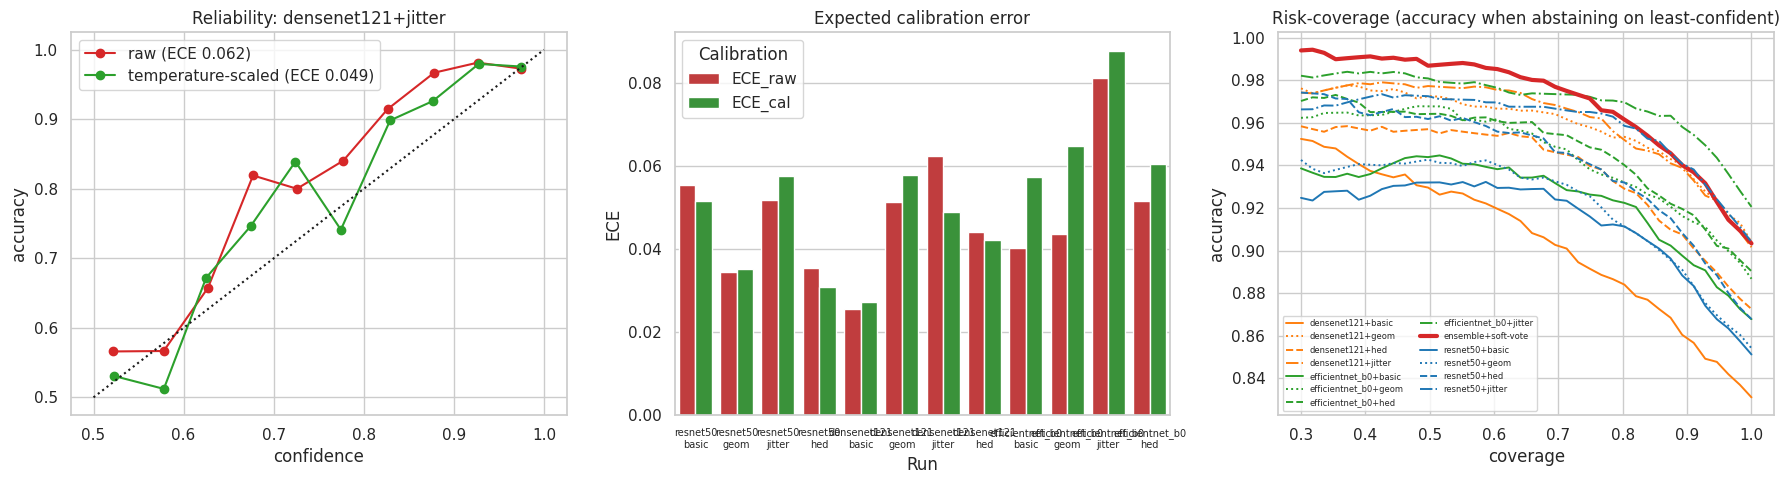

Operating points chosen on validation, evaluated on test (mean over folds):


Recall  Specificity  Recall_HS  Spec_HS  \
Model           Augmentation                                            
densenet121     basic          0.780        0.986      0.842    0.947   
                geom           0.886        0.959      0.798    0.981   
                hed            0.842        0.964      0.918    0.856   
                jitter         0.879        0.971      0.895    0.957   
efficientnet_b0 basic          0.845        0.938      0.741    0.969   
                geom           0.859        0.971      0.797    0.978   
                hed            0.864        0.969      0.839    0.974   
                jitter         0.918        0.928      0.883    0.959   
ensemble        soft-vote      0.877        0.983      0.846    0.990   
resnet50        basic          0.811        0.974      0.789    0.978   
                geom           0.813        0.978      0.866    0.955   
                hed            0.841        0.950      0.907    0.895   
                jitter         0.890        0.945      0.894    0.943   

                              Spec_Youden  Acc_at_90cov  
Model           Augmentation                             
densenet121     basic               0.995         0.859  
                geom                0.998         0.937  
                hed                 0.983         0.906  
                jitter              0.990         0.937  
efficientnet_b0 basic               0.969         0.897  
                geom                0.978         0.914  
                hed                 0.981         0.918  
                jitter              0.959         0.956  
ensemble        soft-vote           1.000         0.939  
resnet50        basic               0.986         0.887  
                geom                0.998         0.886  
                hed                 0.990         0.907  
                jitter              0.983         0.941

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# (a) reliability diagram of the best config, pooled over folds
by, bm = best_cfg[1], best_cfg[0]
for key, lab, c in (("p_raw", "raw", "tab:red"), ("p", "temperature-scaled", "tab:green")):
    y, p = pooled(bm, by, key); conf = np.maximum(p, 1 - p); corr = ((p >= .5).astype(int) == y)
    edges = np.linspace(0.5, 1, 11); xs, ys_ = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.sum() >= 5: xs.append(conf[mk].mean()); ys_.append(corr[mk].mean())
    axes[0].plot(xs, ys_, marker="o", color=c, label=f"{lab} (ECE {ece_score(p, y):.3f})")
axes[0].plot([0.5, 1], [0.5, 1], "k:"); axes[0].set(title=f"Reliability: {bm}+{by}", xlabel="confidence", ylabel="accuracy"); axes[0].legend()

# (b) ECE raw vs calibrated for every single run
e = results_df[results_df.Model != "ensemble"].assign(Run=lambda d: d.Model + "\n" + d.Augmentation)
e = e.melt(id_vars="Run", value_vars=["ECE_raw", "ECE_cal"], var_name="Calibration", value_name="ECE")
sns.barplot(data=e, x="Run", y="ECE", hue="Calibration", errorbar="sd", ax=axes[1], palette=["tab:red", "tab:green"])
axes[1].set_title("Expected calibration error"); axes[1].tick_params(axis="x", labelsize=7)

# (c) risk-coverage
for (m, a), _ in cm_sum.groupby(level=[0, 1]):
    y, p = pooled(m, a); cov, acc = risk_coverage(p, y)
    axes[2].plot(cov, acc, color=col[m], ls=ls[a], lw=3 if m == "ensemble" else 1.4, label=f"{m}+{a}")
axes[2].set(title="Risk-coverage (accuracy when abstaining on least-confident)", xlabel="coverage", ylabel="accuracy")
axes[2].legend(fontsize=6, ncol=2)
fig.tight_layout(); fig.savefig(f"{OUT}/calibration_selective.png", dpi=150, bbox_inches="tight"); plt.show()

print("Operating points chosen on validation, evaluated on test (mean over folds):")
display(results_df.groupby(["Model", "Augmentation"])[["Recall", "Specificity", "Recall_HS", "Spec_HS", "Spec_Youden", "Acc_at_90cov"]].mean().round(3))

## 15. Most confident mistakes of the best config

('densenet121', 'jitter'): 166 mistakes out of 1686 test images (fold 0)


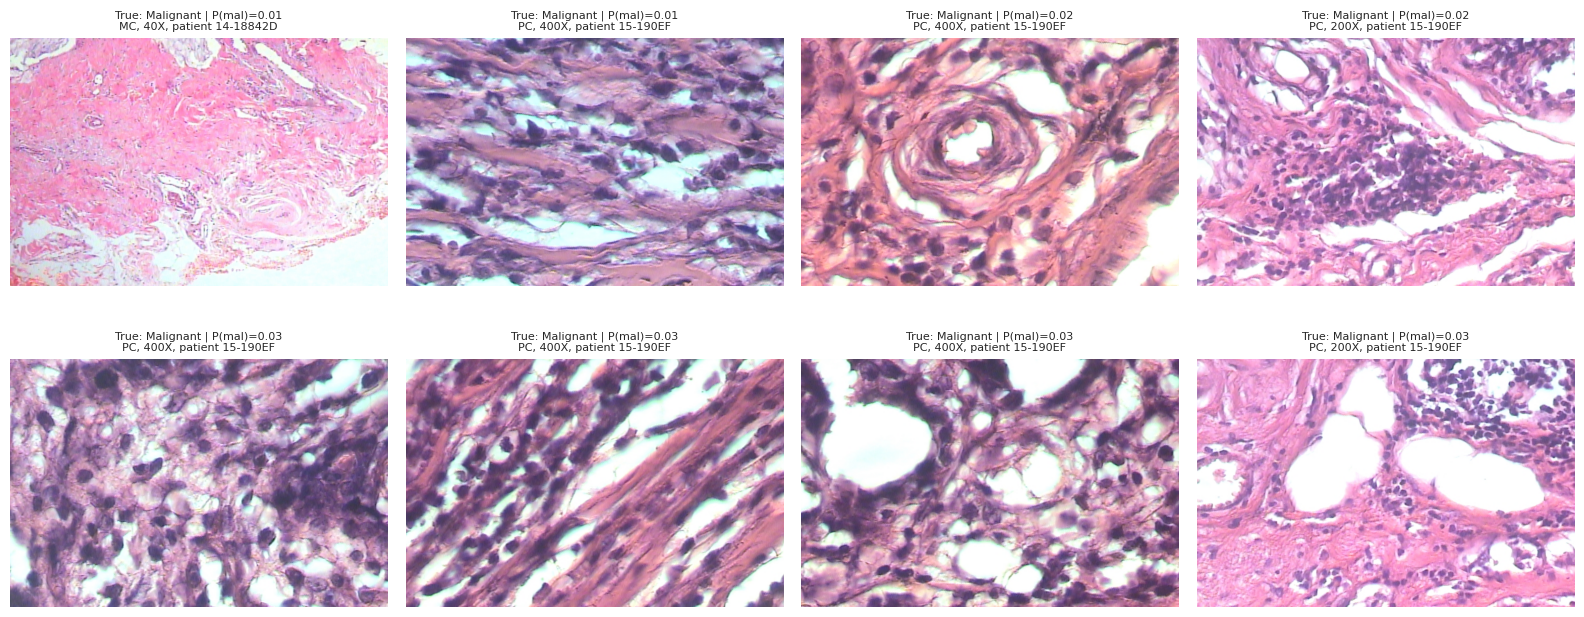

In [15]:
r = RUNS[(best_cfg[0], best_cfg[1], f0)]
y, p, te = r["y"], r["p_raw"], r["test_df"]
bad = np.where((p >= 0.5).astype(int) != y)[0]
bad = bad[np.argsort(-np.abs(p[bad] - 0.5))][:8]
print(f"{best_cfg}: {int(((p >= .5).astype(int) != y).sum())} mistakes out of {len(y)} test images (fold {f0})")
if len(bad):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), bad):
        row = te.iloc[i]; ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(f"True: {CLASS_NAMES[y[i]]} | P(mal)={p[i]:.2f}\n{row.subtype}, {row.magnification}, patient {row.patient}", fontsize=8)
    fig.tight_layout(); fig.savefig(f"{OUT}/misclassified.png", dpi=150, bbox_inches="tight"); plt.show()